In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
import time




bloco = 0
r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_6396\850298442.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv('activity_recognition_data_watch_join_multi_index.csv')

In [4]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [5]:
data.isnull().sum()

pessoa_x          0
atividade         0
tempo             0
acelerômetro_x    0
acelerômetro_Y    0
acelerômetro_Z    0
giroscópio_x      0
giroscópio_Y      0
giroscópio_Z      0
dtype: int64

In [6]:
#remove the null class
data=data.dropna()

# **Data Exploration**

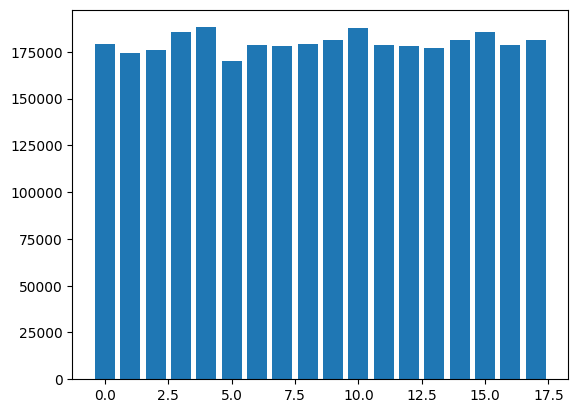

In [7]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

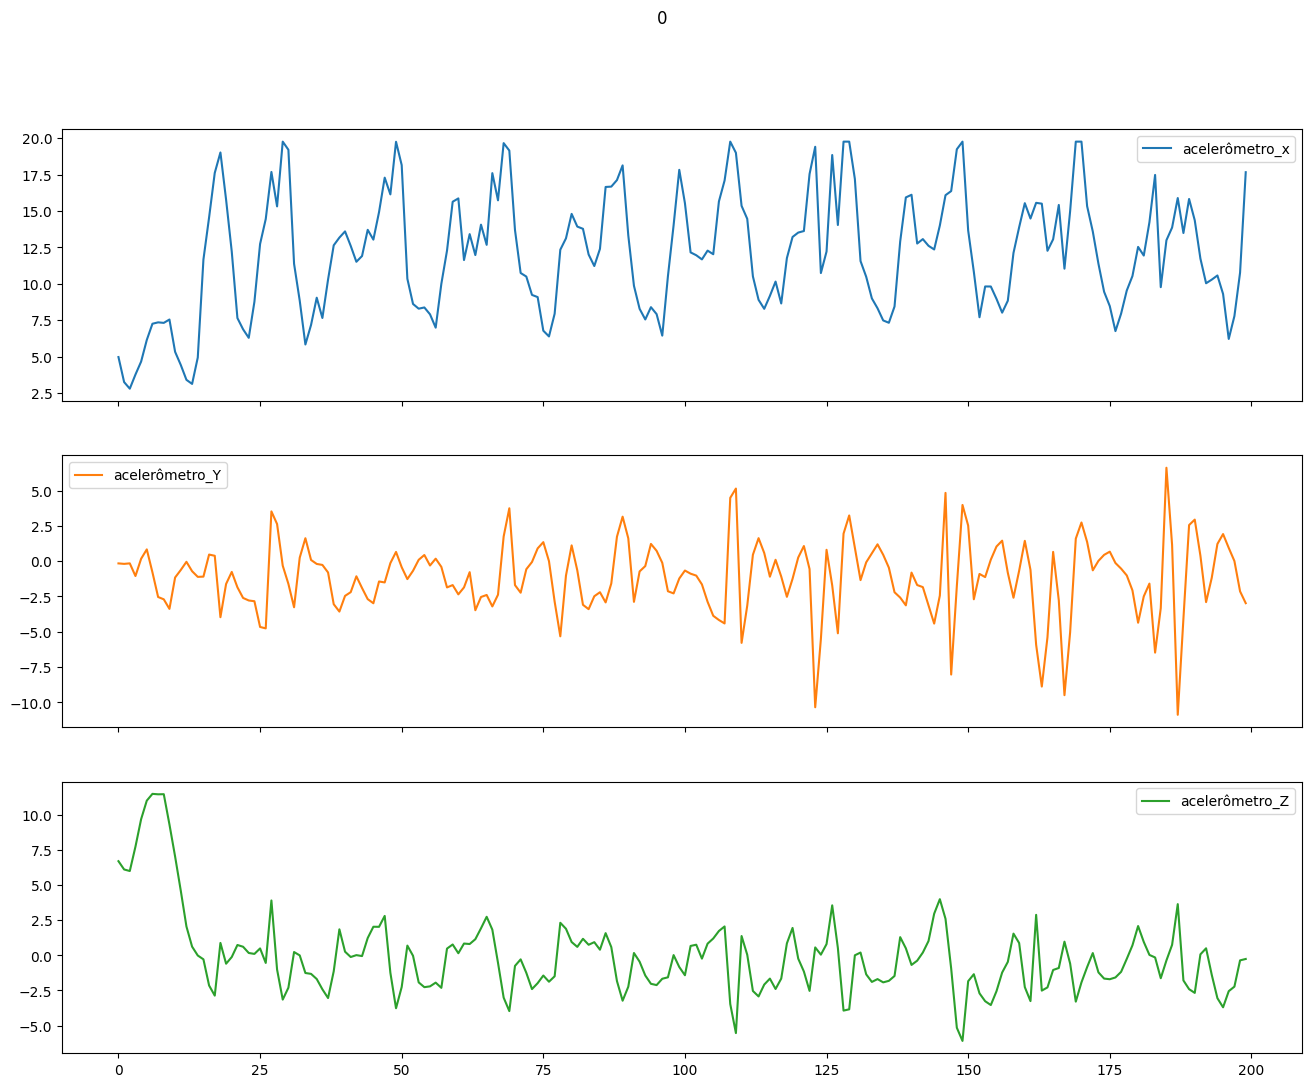

In [8]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

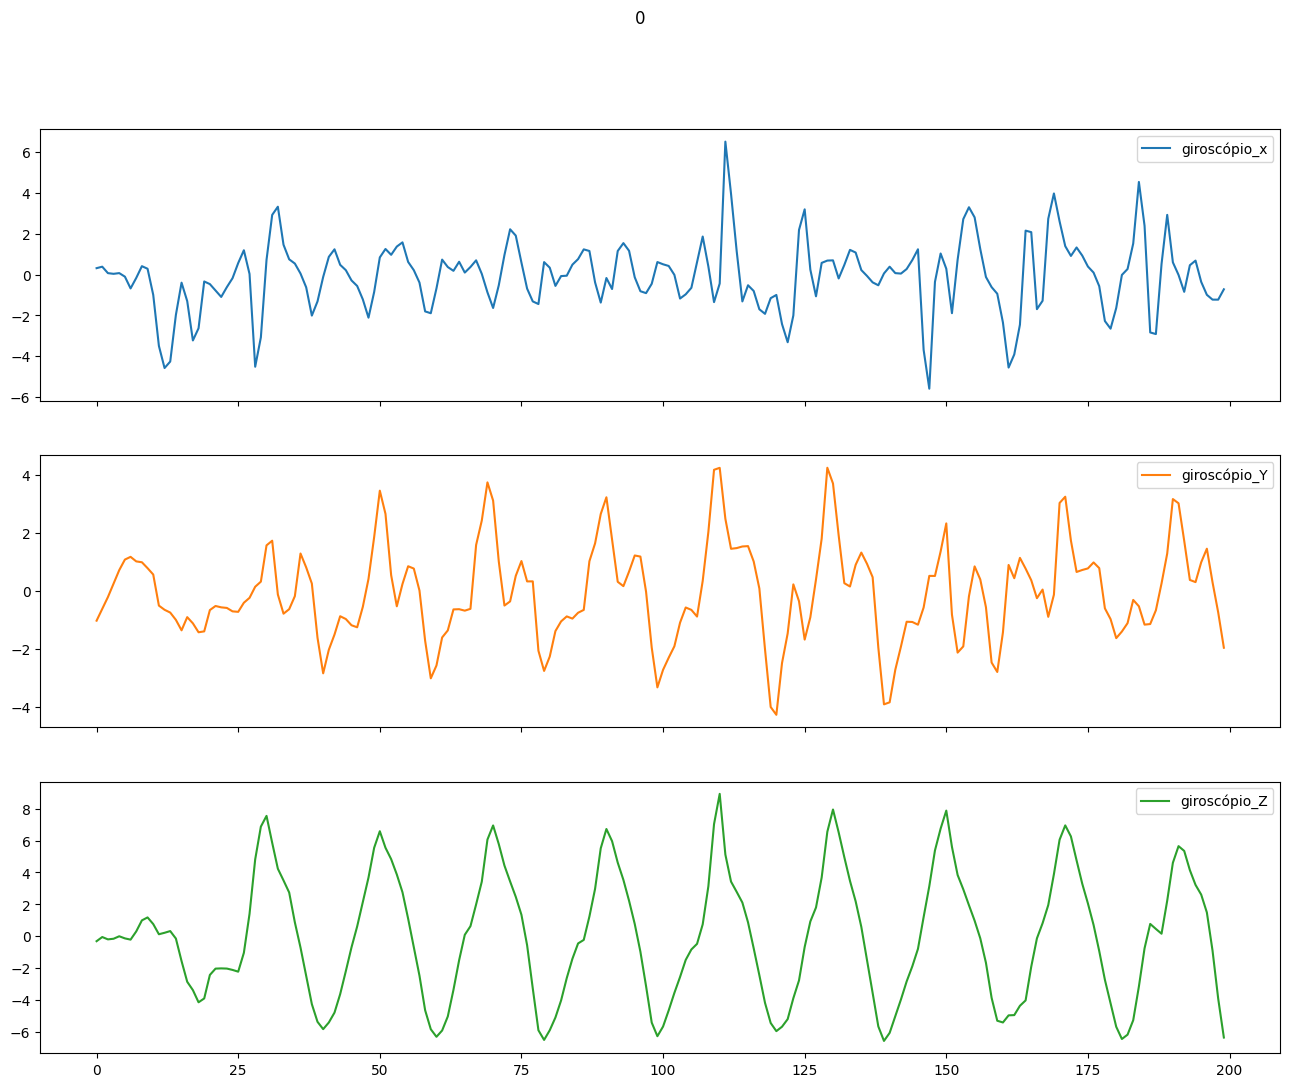

In [9]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

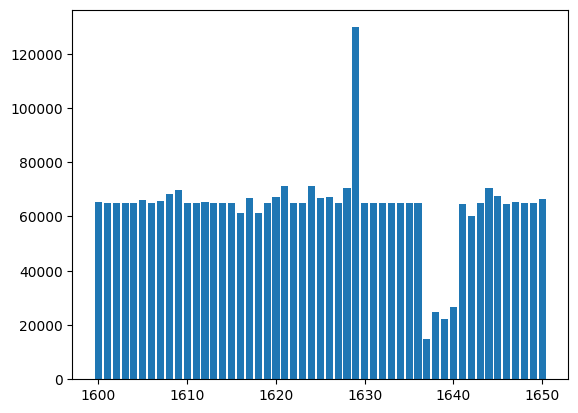

In [10]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [11]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [12]:
data.shape

(714799, 9)

In [13]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [14]:
data = data.reset_index()

In [15]:
data.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [16]:
data.shape

(714799, 10)

# **Models**

In [17]:
def split_indices_for_kfold(validation_sets):
    split_indices = np.empty((5, 2))
    position = 0
    for set in validation_sets:
        start_validation_index = data[(data['pessoa_x'].isin(set))].head(1).index[0]
        end_validation_index = data[(data['pessoa_x'].isin(set))].tail(1).index[0]
        split_indices[position]= [start_validation_index,end_validation_index]
        position = position + 1
    return split_indices       


In [18]:
validation_set1=np.arange(1600,1610)
validation_set2=np.arange(1610,1620)
validation_set3=np.arange(1620,1629)
validation_set4=np.arange(1629,1640)
validation_set5=np.arange(1640,1651)
combined_validation_sets = [validation_set1,validation_set2, validation_set3, validation_set4, validation_set5]
split_indices = split_indices_for_kfold(combined_validation_sets)

In [19]:
print(split_indices[0])

[     0. 144108.]


In [20]:
for elem1,elem2 in split_indices:    
        print(f"{elem1}-{elem2} -- total percentual={(elem2-elem1)/data.shape[0]}")
              

0.0-144108.0 -- total percentual=0.20160632569435605
144109.0-284612.0 -- total percentual=0.19656294986422757
284613.0-418643.0 -- total percentual=0.18750725728491505
418644.0-563854.0 -- total percentual=0.20314801783438421
563855.0-714798.0 -- total percentual=0.21116845434870501


In [21]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [22]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [23]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [24]:
def cria_LSTM():
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(units=160, kernel_regularizer=l2(0.0004704965297508378),
             recurrent_regularizer=l2(0.0004704965297508378), input_shape=(200,6), return_sequences=False))  
  model.add(tf.keras.layers.Dense(units = 96, activation='relu'))  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.0009749332269823054), metrics=['accuracy'])
  return model


In [25]:
def create_validation_and_train_data(start_index,end_index):
    global bloco
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    print("indices que serão processados")
    print("Proximo bloco:")
    print(bloco)
    print(start_index)
    print(end_index)
    
    X_validation_data = data.iloc[int(start_index):int(end_index + 1)]
    X_train_data = data.drop(index=data.index[int(start_index):int(end_index + 1)])
    #print(X_validation_data)
    #print(X_train_data)

    X_validation_data = X_validation_data.reset_index(drop=True)
    X_validation_data = X_validation_data.drop('index',axis=1)
    X_validation_data.info()
    X_validation_data['atividade'].value_counts()
    X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]
    print(X_validation_data.shape)

    X_train_data = X_train_data.reset_index(drop=True)
    X_train_data = X_train_data.drop('index',axis=1)
    X_train_data['atividade'].value_counts()
    X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]
    print(X_train_data.shape)

    segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
    print(targets_val.shape)
    print(segments_val.shape)

    segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
    print(targets_val.shape)
    print(segments_val.shape)
    print("fez a segmentação da validação no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    targets_val = targets_val.reshape(targets_val.shape[0],200)
    print(targets_val.shape)
    print(targets_val)
    labels_val = targets_val[:,0]
    print(labels_val)
    print(labels_val.shape)
    labels_val_categorical = to_categorical(labels_val,num_classes=4)
    print(labels_val_categorical)
    print(labels_val_categorical.shape)
    segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)
    print(segments_train.shape)
    print(targets_train.shape)

    segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
    print(segments_train.shape)
    print(targets_train.shape)
    print("fez a segmentação do treino no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")

    targets_train = targets_train.reshape(targets_train.shape[0],200)
    print(targets_train.shape)
    labels_train = targets_train[:,0]
    labels_train_categorical = to_categorical(labels_train,num_classes=4)
    print(labels_train_categorical)

    X_train = segments_train
    y_train = labels_train_categorical
    X_validation = segments_val
    y_validation = labels_val_categorical

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)

    X_train,y_train = shuffle_data(X_train,y_train)
    X_validation,y_validation = shuffle_data(X_validation,y_validation)

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)
    bloco = bloco+1
    print(f" %%%%%%%%%%%%%%%%%%%%%%%%%%%% retornou os dados para treinamento de {start_index} e {end_index} %%%%%%%%%%%%%%%%%%%%")
    return (X_train,y_train,X_validation,y_validation)

In [26]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

my_callbacks = [early_stopping]  

In [27]:
#for start_index,end_index in split_indices:    
        #print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")     

************ Usando indices 0.0 e 144108.0 como teste ******************* 
Current time in milliseconds: 1708944219704.25
indices que serão processados
Proximo bloco:
0
0.0
144108.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144109 entries, 0 to 144108
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   pessoa_x        144109 non-null  int64  
 1   atividade       144109 non-null  int64  
 2   tempo           144109 non-null  int64  
 3   acelerômetro_x  144109 non-null  float64
 4   acelerômetro_Y  144109 non-null  float64
 5   acelerômetro_Z  144109 non-null  float64
 6   giroscópio_x    144109 non-null  float64
 7   giroscópio_Y    144109 non-null  float64
 8   giroscópio_Z    144109 non-null  float64
dtypes: float64(6), int64(3)
memory usage: 9.9 MB
(144109, 7)
(570690, 7)
(7196, 200, 1)
(7196, 200, 6)
(6809, 200, 1)
(6809, 200, 6)
fez a segmentação da validação no horário
Current time in millisecon

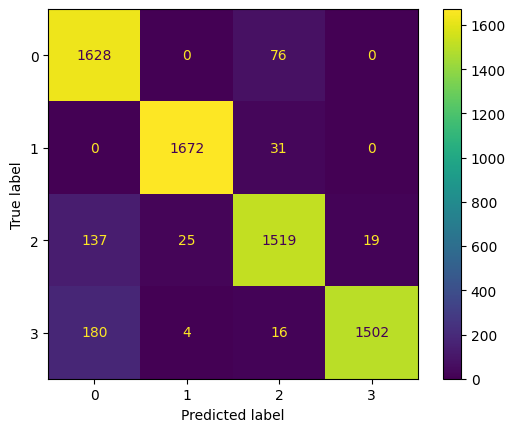

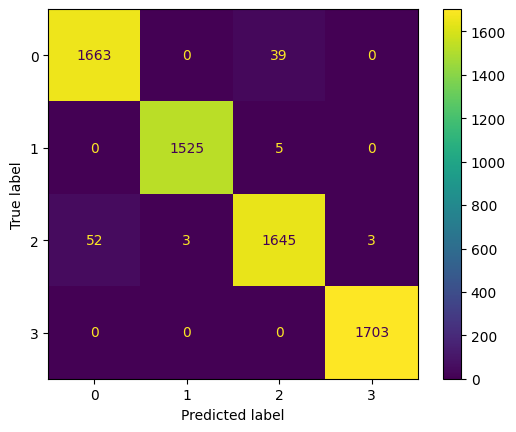

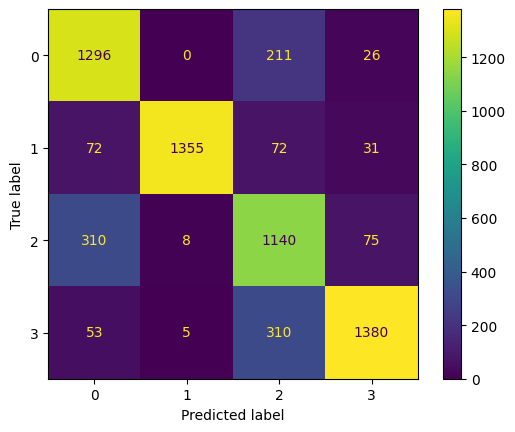

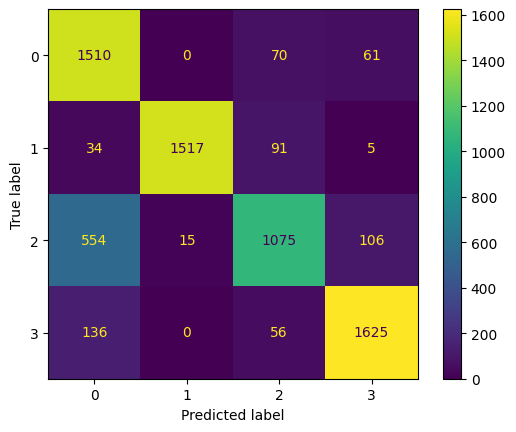

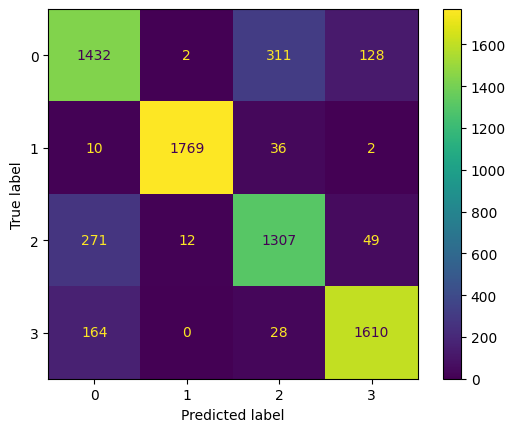

In [28]:
accuracies = []
for start_index,end_index in split_indices:
        print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")    
        X_train,y_train,X_validation,y_validation = create_validation_and_train_data(start_index,end_index)
        print (X_train)
        model  = cria_LSTM()
        model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_validation, y_validation),use_multiprocessing=True,callbacks=[my_callbacks])  # Adjust epochs and batch size
        _, accuracy = model.evaluate(X_validation, y_validation)
        
        print(f"===============>Appending accuracy of {accuracy} ") 
        accuracies.append(accuracy)

        loss, accuracy = model.evaluate(X_validation, y_validation)

        predictions = model.predict(X_validation)
        
        print(y_validation)        
        print(y_validation.shape)

        y_validation_inverse = np.argmax(y_validation, axis=1)
        
        print(y_validation_inverse)
        print(len(y_validation_inverse))
        print(predictions)
        
        classes_x=np.argmax(predictions,axis=1)
        
        print(classes_x)
        print(len(classes_x))
        print(classes_x.shape)
        
        from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
        
        cm = confusion_matrix(y_validation_inverse, classes_x)
        
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()

        print(classification_report(y_validation_inverse, classes_x))

print(f"Average accuracy: {np.mean(accuracies)}")

In [29]:
print(f"Average accuracy: {np.mean(accuracies)}")

Average accuracy: 0.8842915415763855


In [30]:
print(accuracies)

[0.92833012342453, 0.9846339225769043, 0.815100908279419, 0.8354485630989075, 0.8579441905021667]
